In [1]:
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import sncosmo
import yaml
from astropy.io import fits
from astropy.table import Table
from matplotlib import pyplot as plt
from matplotlib.transforms import blended_transform_factory
from tqdm.auto import tqdm

from libech0ez.lcfit import LCFitter, phot_from_snana, plot_fit_comparison


fitter = LCFitter(saltver='T21', saltzp=10.635, mwdust=sncosmo.CCM89Dust)
SUFFIX = f'{fitter.saltver.replace(".", "")}-{fitter.mwdust.__name__[:-4]}'

## Pantheon+

### Filters

In [3]:
idsurveys = yaml.load(open('data/PantheonPlus/IDSURVEYs.yaml'), yaml.SafeLoader)
filtmap = yaml.load(open('data/PantheonPlus/filtmap-kcor.yaml'), yaml.SafeLoader)


def get_band(b, meta):
    return (
        filtmap[meta['SURVEY']].format(b)
        if isinstance(filtmap[meta['SURVEY']], str) else
        filtmap[meta['SURVEY']][b]
    )

In [4]:
from astropy.io.fits.verify import VerifyWarning
from warnings import filterwarnings, catch_warnings

with catch_warnings():
    filterwarnings('ignore', category=VerifyWarning)
    for survey, fname in {
        'Foundation': 'Foundation_v6_1',
        'PS1': 'PS1_v6_1',
        'SWIFT': 'SWIFT_v6_1',
        'LOWZ': 'Land2',
        'PS1_LOWZ_COMBINED': 'PS1_CFA_COMBINED_v6_1',
        'CSP': 'CSPDR3_v6_1',
        'KAITS': 'KAIT_Stahl_v6_1',
        'KAITM': 'KAIT_Mo_v6_1'
    }.items():
        f = fits.open(f'data/PantheonPlus/kcor/kcor_{fname}.fits')
        for name, trans in Table(f['FilterTrans'].data).to_pandas().set_index('wavelength (A)').items():
            print(name := f'SNANA::{survey}::{name}')
            sncosmo.register(sncosmo.Bandpass(trans.index, trans, name=name), force=True)

        primaries = {
            key: sncosmo.SpectralMagSystem(sncosmo.SpectrumModel(val.index, val))
            for key, val in Table(f['PrimarySED'].data).to_pandas().set_index('wavelength (A)').items()
        }

        sncosmo.register(sncosmo.CompositeMagSystem({
            f'SNANA::{survey}::{key.strip()}': (primaries[row['Primary Name'].strip()], row['Primary Mag'])
            for key, row in Table(f['ZPoff'].data).to_pandas().set_index('Filter Name').iterrows()
        }, name=survey), force=True)

SNANA::Foundation::PS1-g
SNANA::Foundation::PS1-r
SNANA::Foundation::PS1-i
SNANA::Foundation::PS1-z
SNANA::Foundation::PS1-y
SNANA::PS1::PS1-g
SNANA::PS1::PS1-r
SNANA::PS1::PS1-i
SNANA::PS1::PS1-z
SNANA::PS1::PS1-y
SNANA::PS1::*PS1-g
SNANA::PS1::*PS1-r
SNANA::PS1::*PS1-i
SNANA::PS1::*PS1-z
SNANA::PS1::*PS1-y
SNANA::SWIFT::UVOT-U
SNANA::SWIFT::UVOT-B
SNANA::SWIFT::UVOT-V
SNANA::SWIFT::UVOT-X
SNANA::SWIFT::UVOT-N
SNANA::SWIFT::UVOT-W
SNANA::LOWZ::Bessell-U
SNANA::LOWZ::Bessell-B
SNANA::LOWZ::Bessell-V
SNANA::LOWZ::Bessell-R
SNANA::LOWZ::Bessell-I
SNANA::PS1_LOWZ_COMBINED::CFA3S-U/a
SNANA::PS1_LOWZ_COMBINED::CFA3S-B/b
SNANA::PS1_LOWZ_COMBINED::CFA3S-V/c
SNANA::PS1_LOWZ_COMBINED::CFA3S-R/d
SNANA::PS1_LOWZ_COMBINED::CFA3S-I/e
SNANA::PS1_LOWZ_COMBINED::CFA41-U/f
SNANA::PS1_LOWZ_COMBINED::CFA41-B/g
SNANA::PS1_LOWZ_COMBINED::CFA41-V/h
SNANA::PS1_LOWZ_COMBINED::CFA41-r/i
SNANA::PS1_LOWZ_COMBINED::CFA41-i/j
SNANA::PS1_LOWZ_COMBINED::CFA41-U/k
SNANA::PS1_LOWZ_COMBINED::CFA41-B/l
SNANA::PS1_LOWZ_C

### Data

In [5]:
pplus_raw = (
    pd.read_csv('data/PantheonPlus/Pantheon+SH0ES.dat', delimiter=' ').set_index('CID')
    .assign(
        **pd.read_csv('data/PantheonPlus/SH0ES-tbl6.csv').set_index('CID')
        [['HOST', 'CEPH_DIST', 'CEPH_DISTERR', 'HOST_DIST', 'HOST_DISTERR', 'R']])
    .rename(columns={
        'PKMJD': 't0', 'PKMJDERR': 't0_err', 'mB': 'm', 'mBERR': 'm_err',
        'x1ERR': 'x1_err', 'cERR': 'c_err'})
    .sort_values('m_b_corr_err_DIAG')
)

pplus_raw.loc[(pplus_raw.index.isin((
    '2007A', '2009Y',
    '2009do',
    '2009bv',
    '2007kk',
    '2008051',
    '2008gb',
    '2007is',
    '2008Y',
    '2008050',
    '2008fr',
    '2007sw',
    '2007kh',
))) * (pplus_raw['IDSURVEY'] == 65), 'IDSURVEY'] = 67

pplus_raw['SURVEY'] = [idsurveys[idsurvey] for idsurvey in pplus_raw['IDSURVEY']]

In [6]:
pplus_dedup_raw = pplus_raw[pplus_raw['SURVEY'].isin(filtmap)].reset_index().drop_duplicates('CID').set_index('CID')

_res_index = []
for _ in pplus_dedup_raw.index:
    try:
        _res_index.append(int(_))
    except:
        _res_index.append(_)
pplus_dedup_raw.index = pd.Index(_res_index, name=pplus_dedup_raw.index.name)
pplus_dedup_raw.to_csv('data/pplus-dd.csv')

sdd_raw = pplus_dedup_raw[pplus_dedup_raw['USED_IN_SH0ES_HF'].astype(bool)]
cdd_raw = pplus_dedup_raw[pplus_dedup_raw['IS_CALIBRATOR'].astype(bool)]

len(sdd_raw), len(cdd_raw), set(pplus_raw.index[pplus_raw['IS_CALIBRATOR'].astype(bool)]) - set(cdd_raw.index)

(191, 41, {'2021pit'})

In [6]:
pplus_lcs = defaultdict(dict)

tq = tqdm()
for l in Path('data/PantheonPlus/photometry').rglob('*.LIST', case_sensitive=True):
    for fname in open(l).readlines():
        if fname.startswith('#'):
            continue

        fname = l.parent / fname.rstrip(' \r\n')
        if not fname.is_file():
            print('NOT FOUND', fname)

        if fname.suffix.lower().endswith('gz'):
            print('GZIP', fname)
        else:
            try:
                meta, t = sncosmo.read_snana_ascii(str(fname), default_tablename='OBS')
                t = t['OBS']
                t.meta = meta

                pplus_lcs[t.meta['SNID']][t.meta['SURVEY']] = t
            except Exception as e:
                print('ERROR', fname.name, e)
        tq.update(1)

pplus_lcs['2008fv'] = pplus_lcs.pop('2008fv_comb')
len(pplus_lcs)

0it [00:00, ?it/s]

GZIP data/PantheonPlus/photometry/JLA2014_SDSS_DS17/JLA2014_SDSS_DS17_HEAD.FITS.gz
ERROR LOWZ_JRK07_1998ec.DAT 'SURVEY'


1791

### Fit

In [7]:
(cdd_fit, _), (sdd_fit, _) = (fitter(raw, {
    snid: phot_from_snana(phot, get_band)
    for snid, row in raw.iterrows()
    for phot in [pplus_lcs[snid][row['SURVEY']]]
    if snid in pplus_lcs and row['SURVEY'] in filtmap
}) for raw in (cdd_raw, sdd_raw))

  0%|          | 0/41 [00:00<?, ?it/s]

  0%|          | 0/191 [00:00<?, ?it/s]

#### Export

In [8]:
for df_fit, prefix in ((cdd_fit, 'pplus-cdd'), (sdd_fit, 'pplus-sdd')):
    df_fit.rename_axis(index='CID').assign(**pplus_dedup_raw[[
        'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'zHD', 'zHDERR',
        'HOST', 'HOST_DIST', 'HOST_DISTERR'
    ]].loc[df_fit.index]).to_csv(f'data/{prefix}_{SUFFIX}.csv')

In [10]:
_pplus_dedup_raw = pplus_raw.reset_index().drop_duplicates('CID').set_index('CID')
for df_raw, prefix in (
    (_pplus_dedup_raw[_pplus_dedup_raw['IS_CALIBRATOR'].astype(bool)], 'pplus-cdd'),
    (_pplus_dedup_raw[_pplus_dedup_raw['USED_IN_SH0ES_HF'].astype(bool)], 'pplus-sdd')):
    df_raw.rename(columns={
        'x0ERR': 'x0_err',
        'COV_x1_x0': 'cov_x0_x1', 'COV_c_x0': 'cov_x0_c', 'COV_x1_c': 'cov_x1_c'
    }).assign(m=df_raw['m']+0.27).to_csv(f'data/{prefix}_nom.csv')

### Examine

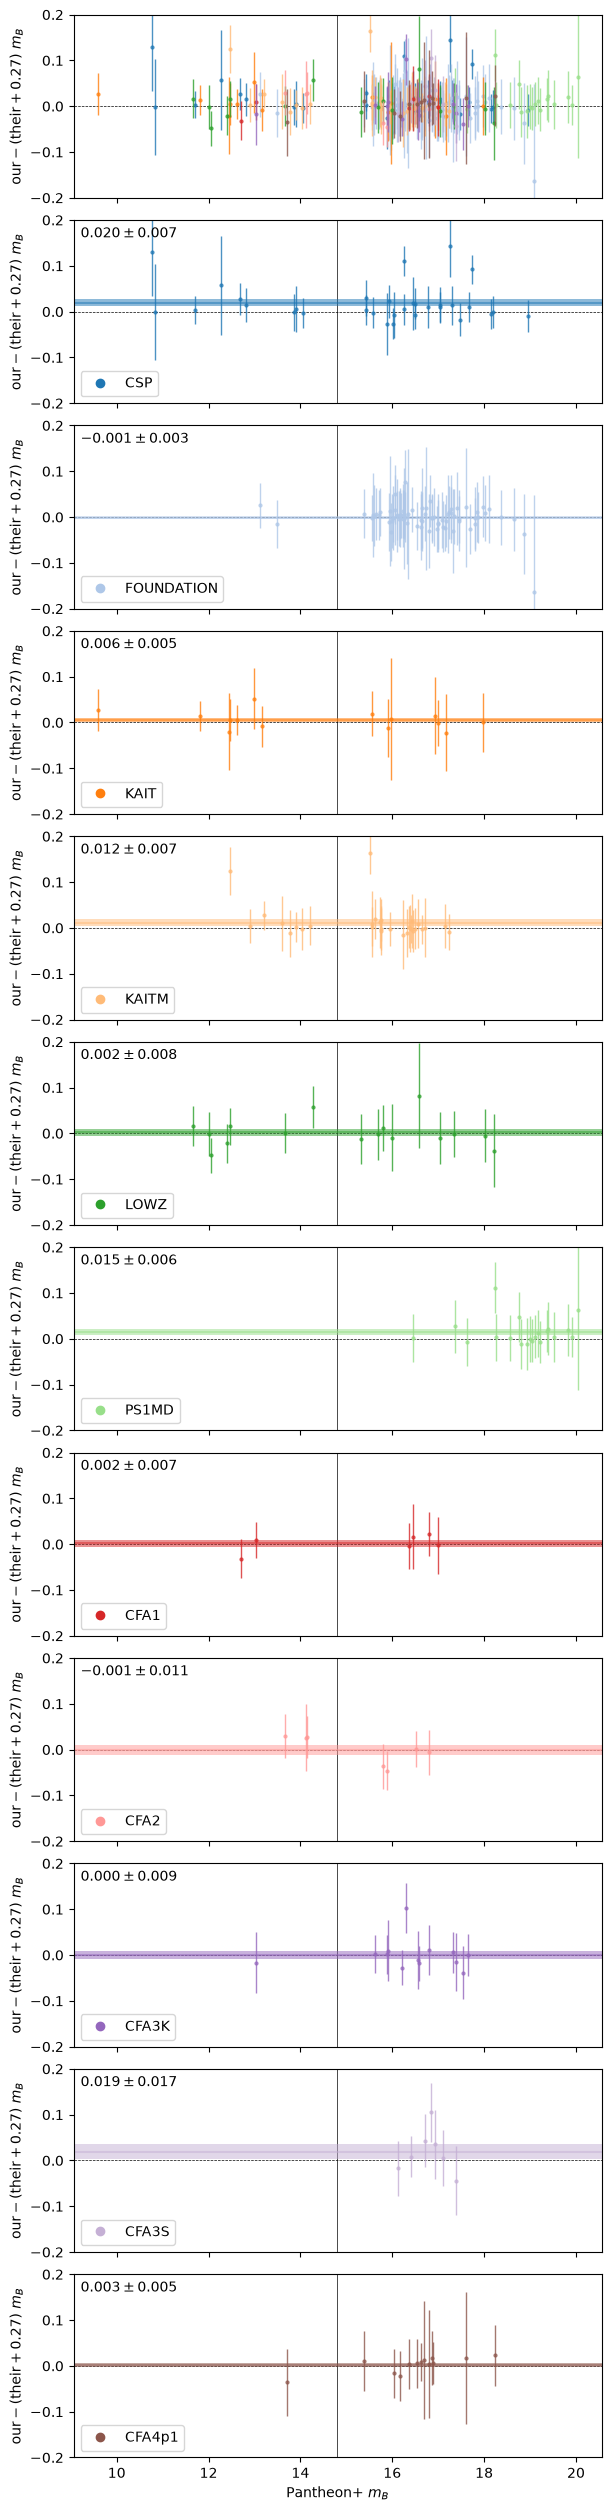

In [9]:
ref = pd.concat((cdd_raw, sdd_raw))
res = pd.concat((cdd_fit, sdd_fit))
# ref = cdd_raw
# res = cdd_fit
df = ref.assign(
    dm=res['m']-(ref['m']+0.27),
    dm_err=(ref['m_err']**2+res['m_err']**2)**0.5,
    dx1=res['x1']-ref['x1'],
    dx1_err=(ref['x1_err']**2+res['x1_err']**2)**0.5,
    dc=res['c']-ref['c'],
    dc_err=(ref['x1_err']**2+res['c_err']**2)**0.5,
)

cmap = plt.get_cmap('tab20')
grouped = df.groupby('SURVEY')


fig, axs = plt.subplots(len(grouped)+1, 1, sharex=True, sharey=True, constrained_layout=True, figsize=(6, (len(grouped)+1)*2+1))

for i, (key, group) in enumerate(grouped):
    x = group['m']
    y = group['dm']  # - 0.13*group['dx1']
    err = group['dm_err']

    w = np.ones_like(x)  # 1/err**2
    smean = np.average(y, weights=w)
    svar = np.average(y**2, weights=w) - smean**2
    neff = w.sum()**2 / (w**2).sum()
    sstd = (svar/neff)**0.5

    clr = cmap(i%cmap.N)

    for ax in (axs[0], axs[1+i]):
        ax.errorbar(x, y, err, color=clr, ls='none', alpha=0.8, lw=1, zorder=1)
        ax.plot(x, y, 'o', ms=3, mew=0, color=clr, alpha=0.8, zorder=1)

    for nsigma in (1,):
        axs[1+i].fill_between(
            [0, 1], smean-nsigma*sstd, smean+nsigma*sstd,
            color=clr, alpha=0.5, zorder=0, lw=0,
            transform=blended_transform_factory(axs[1+i].transAxes, axs[1+i].transData)
        )
    axs[1+i].axhline(smean, color=clr, alpha=0.5, zorder=0)
    axs[1+i].annotate(fr'${smean:.3f}\pm{sstd:.3f}$', (0, 1), (0.5, -0.5), xycoords=axs[1+i].transAxes, textcoords='offset fontsize', ha='left', va='top')
    axs[1+i].legend(handles=[plt.Line2D([], [], ls='none', marker='o', color=clr, label=key.rsplit('PS1_LOWZ_COMBINED(')[-1].strip(')'))], loc='lower left')

for ax in axs:
    ax.axhline(0, color='k', ls='--', lw=0.5, zorder=-1)
    ax.axvline(14.8, color='k', lw=0.5, zorder=-1)
    ax.set(ylabel=r'$\mathrm{our} - (\mathrm{their}+0.27)$ $m_B$', ylim=(-0.2, 0.2))
axs[-1].set(xlabel='Pantheon+ $m_B$');

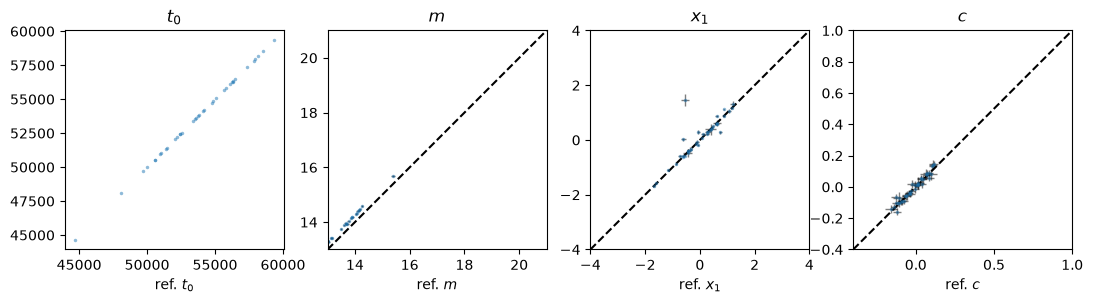

In [10]:
fig, axs = plot_fit_comparison(cdd_raw, cdd_fit)

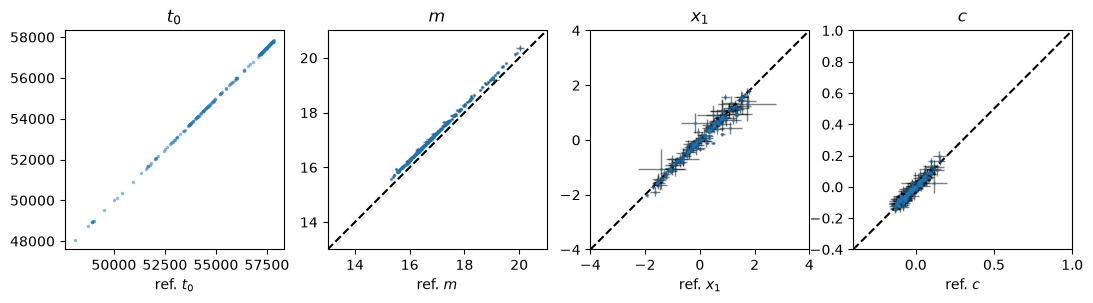

In [11]:
fig, axs = plot_fit_comparison(sdd_raw, sdd_fit)

### Covariance

In [11]:
from astropy.io import fits

L = fits.open('data/PantheonPlus/alll_shoes_ceph_topantheonwt6.0_112221.fits')[0].data.T
y = fits.open('data/PantheonPlus/ally_shoes_ceph_topantheonwt6.0_112221.fits')[0].data
C = fits.open('data/PantheonPlus/allc_shoes_ceph_topantheonwt6.0_112221.fits')[0].data

In [12]:
keep_idx = np.full_like(y, True, dtype=bool)
keep_idx[3130:3130+77] = False
keep_idx[-277:] = False

L_ = L[np.ix_(keep_idx, 37*[True]+[True, True, True, True, True, False, True, True, True, False])]
y_ = y[keep_idx]
C_ = C[np.ix_(keep_idx, keep_idx)]

Cinv_ = np.linalg.inv(C_)
Cq_ = np.linalg.inv(L_.T @ Cinv_ @ L_)
q_ = Cq_ @ L_.T @ Cinv_ @ y_

In [13]:
tbl2 = pd.read_csv('data/PantheonPlus/SH0ES-tbl2.csv')
tbl6 = pd.read_csv('data/PantheonPlus/SH0ES-tbl6.csv')

hostlist = tbl2['Field'].unique()[:tbl6['HOST'].nunique()]
(hostlist == tbl6['HOST'].sort_values().drop_duplicates()).all()

np.True_

In [14]:
np.savez(
    'data/pplus-cdd-hosts.npz',
    hostlist=hostlist,
    distmod_calib_mean=q_[:37],
    distmod_calib_cov=Cq_[:37, :37]
)

## ZTF

In [2]:
ztf_raw = pd.read_csv('data/ztfdr2/tables/snia_data.csv').drop(columns={'Unnamed: 0'}).set_index('ztfname')
ztf_raw = ztf_raw[
    (ztf_raw['lccoverage_flag'] == 1)
    # * (ztf_raw['fitquality_flag'] == 1)
    * (ztf_raw['redshift'] <= 0.06)
    # * (ztf_raw['sub_type'] == 'norm')
].dropna()

ztf_host = pd.read_csv('data/ztfdr2/tables/globalhost_data.csv').set_index('ztfname')
ztf_raw = ztf_raw.assign(**ztf_host.loc[ztf_raw.index])

In [3]:
def load_ztf_data(snid, t0):
    data = Table.read(f'data/ztfdr2/lightcurves/{snid}_lc.csv', format='ascii')
    data['zpsys'] = 'ab'
    data['band'] = data['filter']
    del data['filter']

    # Rigault+2025b, section 3.....
    data['flux_err'] = (data['flux_err']**2 + (data['flux'] * (
        np.where(data['band'] == 'ztfg', 0.025,
        np.where(data['band'] == 'ztfr', 0.035,
        np.where(data['band'] == 'ztfi', 0.060, 0)))
    ))**2)**0.5

    dt = (data['mjd'] - t0) / (1+ztf_raw.loc[snid, 'redshift'])
    return data[
        (dt >= -10) * (dt <= 40)
        * (data['flag'] & (1|2|4|8|16) == 0)
        * (data['flux'] > 0)
    ]

ztf_phots = {
    snid: load_ztf_data(snid, row['t0'])
    for snid, row in ztf_raw.iterrows()
}

### Fit

In [4]:
ztf_fit, ztf_ress = fitter(ztf_raw.rename(columns={'redshift': 'zHEL', 'mwebv': 'MWEBV'}), ztf_phots)

  0%|          | 0/1058 [00:00<?, ?it/s]

In [5]:
good_ztf = (
    ztf_fit['success']
    * (abs(ztf_fit['t0'] - ztf_raw['t0']) < 1)
    * (ztf_raw['sub_type'] == 'norm')
    # * (ztf_raw['fitquality_flag'] == 1)
    * (ztf_fit['x1'] > -3) * (ztf_fit['x1'] < 3)
    * (ztf_fit['x1_err'] < 1)
    * (ztf_fit['c'] > -0.2) * (ztf_fit['c'] < 0.8)
    * (ztf_fit['c_err'] < 0.1)
    * (ztf_fit['fitprob'] > 1e-7)
).dropna().astype(bool)
good_ztf_idx = good_ztf.index[good_ztf]
len(good_ztf_idx)

764

#### Export

In [6]:
ztf_fit.assign(**ztf_host.loc[ztf_fit.index], zHEL_err=ztf_raw.loc[ztf_fit.index, 'redshift_err']).loc[good_ztf_idx].rename_axis(index='ztfname').to_csv(f'data/ztfdr2-vlhq_{SUFFIX}.csv')

In [7]:
ztf_ref = ztf_raw.assign(
    m=fitter.salt_zp + (-2.5*np.log10(ztf_raw['x0'])),
    m_err = 2.5 / np.log(10) * ztf_raw['x0_err'] / ztf_raw['x0']
)

In [8]:
ztf_ref.assign(zHEL=ztf_ref['redshift'], zHEL_err=ztf_ref['redshift_err'])[
    (ztf_ref['sub_type'] == 'norm')
    * (ztf_ref['lccoverage_flag'] == 1)
    * (ztf_ref['fitquality_flag'] == 1)
    * (ztf_ref['redshift'] <= 0.06)
].to_csv('data/ztfdr2-vlhq_nom.csv')